In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from keras.models import Sequential
from keras.layers import Dense, Dropout, Input
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.model_selection import train_test_split
from pyswarm import pso
import seaborn as sns


In [ ]:
data = pd.read_csv('../data/ROP.csv')

print("نمایش چند ردیف ابتدایی از داده‌ها:")
print(data.head())


نمایش چند ردیف ابتدایی از داده‌ها:
        D (ft)  WOB (KIbf)  N (rpm)  bit Diameter (in)   T (Ibf.ft)  \
0  1645.000053     0.00862    92.90              12.25   549.999889   
1  1673.231681     0.00628   126.45              12.25  3139.999365   
2  1706.040081     0.00934    89.00              12.25   199.999960   
3  1738.848481     0.00964    89.00              12.25    79.999984   
4  1771.670004     0.00515   128.80              12.25  2439.999506   

      Q (gpm)  Mud Density (Ibm/gal)    SPP (psi)  ROP (ft/h)  
0  745.490042              10.097934  1372.992483   82.560003  
1  782.240045              10.097934  1495.772705  164.450005  
2  782.240045              10.097934  1474.022666   97.860003  
3  782.240045              10.097934  1474.422666   86.580003  
4  782.240045              10.097934  1466.452651  102.740003  


In [3]:
print("\nوجود NaN در داده‌ها:")
print(data.isnull().values.any())



وجود NaN در داده‌ها:
True


In [4]:
X = data.iloc[:, :-1].values
y = data.iloc[:, -1].values

scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X)

X_scaled = X_scaled[~np.isnan(X_scaled).any(axis=1)]
y = y[~np.isnan(y)]


print("\nتعداد نمونه‌ها پس از حذف NaN:")
print(len(X_scaled), len(y))



تعداد نمونه‌ها پس از حذف NaN:
4223 4223


In [6]:
stats = data.agg(['mean','max','min'])
stats.to_excel('statistical_parameters.xlsx', sheet_name='Stats')

print("The statistical parameters have been saved to 'statistical_parameters.xlsx'.")

The statistical parameters have been saved to 'statistical_parameters.xlsx'.


In [7]:
X_train, X_temp, y_train, y_temp = train_test_split(X_scaled, y, test_size=0.3, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)

print(f"تعداد نمونه‌های آموزش: {len(X_train)}")
print(f"تعداد نمونه‌های اعتبارسنجی: {len(X_val)}")
print(f"تعداد نمونه‌های تست: {len(X_test)}")


تعداد نمونه‌های آموزش: 2956
تعداد نمونه‌های اعتبارسنجی: 633
تعداد نمونه‌های تست: 634


In [11]:
def objective_function(params):
    model = Sequential()
    model.add(Input(shape=(X_train.shape[1],)))
    model.add(Dense(512, activation='relu'))
    model.add(Dropout(params[0]))
    model.add(Dense(256, activation='relu'))
    model.add(Dropout(params[1]))
    model.add(Dense(128, activation='relu'))
    model.add(Dropout(params[2]))
    model.add(Dense(64, activation='relu'))
    model.add(Dropout(params[3]))
    model.add(Dense(1))
    model.compile(loss='mean_squared_error', optimizer='adam')
    
    history = model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=70, batch_size=32, verbose=0)  
    y_pred = model.predict(X_val)
    mse = mean_squared_error(y_val, y_pred)
    return mse

In [12]:
lb = [0.1, 0.1, 0.1, 0.1] 
ub = [0.5, 0.5, 0.5, 0.5]


In [35]:
params_opt, _ = pso(objective_function, lb, ub, swarmsize=15, maxiter=15)

print("Optimal dropout rates found:", params_opt)


20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
20/20 ━━━━━━━━━━━━━━━━━━━

In [36]:
final_model = Sequential()
final_model.add(Input(shape=(X_train.shape[1],)))
final_model.add(Dense(512, activation='relu'))
final_model.add(Dropout(params_opt[0]))
final_model.add(Dense(256, activation='relu'))
final_model.add(Dropout(params_opt[1]))
final_model.add(Dense(128, activation='relu'))
final_model.add(Dropout(params_opt[2]))
final_model.add(Dense(64, activation='relu'))
final_model.add(Dropout(params_opt[3]))
final_model.add(Dense(1))
final_model.compile(loss='mean_squared_error', optimizer='adam')


In [37]:
final_model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=1500, batch_size=32, verbose=1)


Epoch 1/1500
93/93 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 15056.1738 - val_loss: 1957.0681
Epoch 2/1500
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 2362.7739 - val_loss: 1513.9822
Epoch 3/1500
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 2186.3328 - val_loss: 1426.2694
Epoch 4/1500
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 2023.7264 - val_loss: 1437.5537
Epoch 5/1500
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1916.4396 - val_loss: 1441.2627
Epoch 6/1500
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1931.9983 - val_loss: 1387.2793
Epoch 7/1500
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1908.4408 - val_loss: 1281.3875
Epoch 8/1500
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1768.5386 - val_loss: 1271.8928
Epoch 9/1500
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1847.4225 - val_loss: 1238.7340
Epoch 10/1500
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 1888.4355 - val_loss: 1226.9618
Epoch 11/1500
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1711.0211 - val_l

In [38]:
y_pred_test = final_model.predict(X_test)

r2_test = r2_score(y_test, y_pred_test)
rmse_test = mean_squared_error(y_test, y_pred_test, squared=False)
print("R^2 برای داده‌های تست:", r2_test)
print("RMSE برای داده‌های تست:", rmse_test)


20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
R^2 برای داده‌های تست: 0.9853005200400391
RMSE برای داده‌های تست: 8.513917191716558


d:\anaconda\lib\site-packages\sklearn\metrics\_regression.py:483: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(


In [39]:
y_pred_val = final_model.predict(X_val)

r2_val = r2_score(y_val, y_pred_val)
rmse_val = mean_squared_error(y_val, y_pred_val, squared=False)
print("R^2 برای داده‌های اعتبارسنجی:", r2_val)
print("RMSE برای داده‌های اعتبارسنجی:", rmse_val)

20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
R^2 برای داده‌های اعتبارسنجی: 0.979733094018881
RMSE برای داده‌های اعتبارسنجی: 10.2094391100013


d:\anaconda\lib\site-packages\sklearn\metrics\_regression.py:483: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(


In [40]:
y_pred_train = final_model.predict(X_train)

r2_train = r2_score(y_train, y_pred_train)
rmse_train = mean_squared_error(y_train, y_pred_train, squared=False)
print("R^2 برای داده‌های آموزشی:", r2_train)
print("RMSE برای داده‌های آموزشی:", rmse_train)


93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
R^2 برای داده‌های آموزشی: 0.9857955438992256
RMSE برای داده‌های آموزشی: 8.486584433969483


d:\anaconda\lib\site-packages\sklearn\metrics\_regression.py:483: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(


In [41]:
results = pd.DataFrame({
    'Data Set': ['Training', 'Validation', 'Test'],
    'R²': [r2_train, r2_val, r2_test],
    'RMSE': [rmse_train, rmse_val, rmse_test]
})

results.to_excel('model_performance.xlsx', index=False)

print("معیارهای عملکرد مدل در فایل 'model_performance.xlsx' ذخیره شدند.")

معیارهای عملکرد مدل در فایل 'model_performance.xlsx' ذخیره شدند.


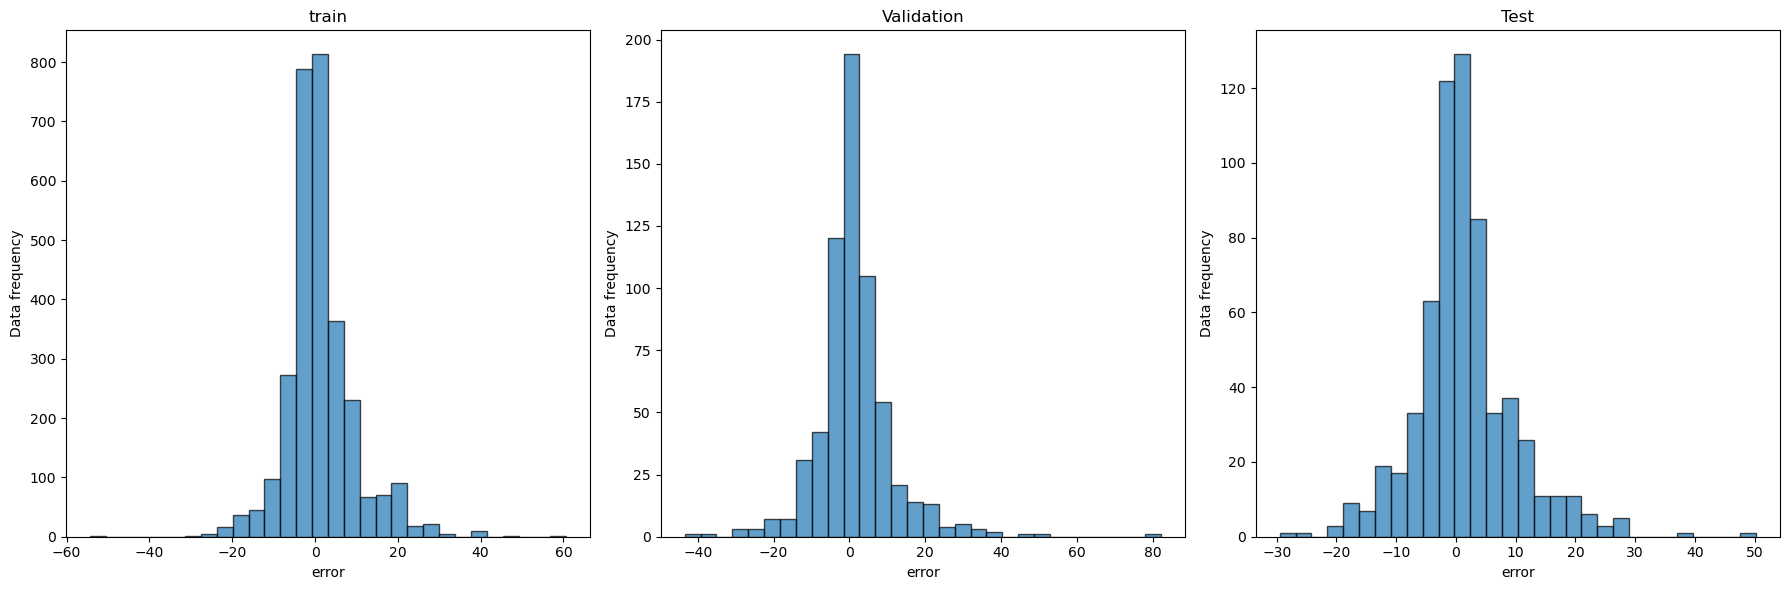

In [42]:
train_errors = y_train - y_pred_train.flatten()
val_errors = y_val - y_pred_val.flatten()
test_errors = y_test - y_pred_test.flatten()

plt.figure(figsize=(18, 6))

plt.subplot(1, 3, 1)
plt.hist(train_errors, bins=30, edgecolor='k', alpha=0.7)
plt.title('train')
plt.xlabel('error')
plt.ylabel('Data frequency')

plt.subplot(1, 3, 2)
plt.hist(val_errors, bins=30, edgecolor='k', alpha=0.7)
plt.title('Validation')
plt.xlabel('error')
plt.ylabel('Data frequency')

plt.subplot(1, 3, 3)
plt.hist(test_errors, bins=30, edgecolor='k', alpha=0.7)
plt.title('Test')
plt.xlabel('error')
plt.ylabel('Data frequency')

plt.tight_layout()
plt.show()

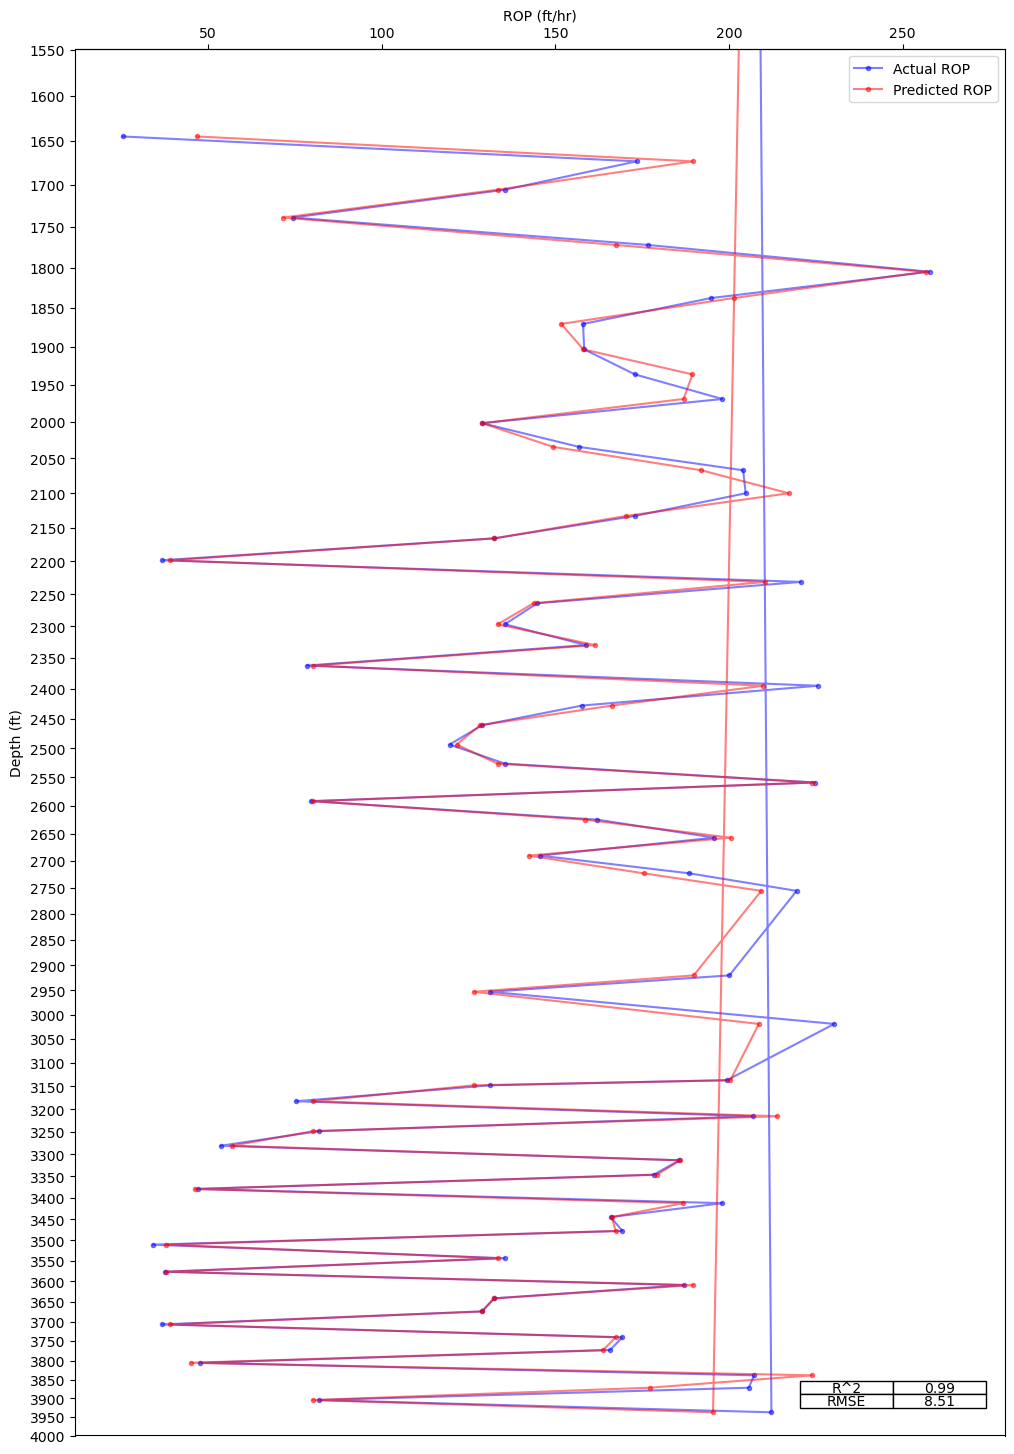

In [43]:
fig, ax = plt.subplots(figsize=(12, 18))

ax.plot(y_test, data['D (ft)'][:len(y_test)], 'bo-', markersize=3, alpha=0.5, label='Actual ROP')  
ax.plot(y_pred_test, data['D (ft)'][:len(y_test)], 'ro-', markersize=3, alpha=0.5, label='Predicted ROP')  

ax.set_ylim(1550, 4000)
ax.invert_yaxis()

ax.set_yscale('log')

yticks = np.arange(1550, 4001, 50)
ax.set_yticks(yticks)
ax.set_yticklabels([str(i) for i in yticks])
ax.set_ylabel('Depth (ft)')

ax_top = ax.secondary_xaxis('top')
ax_top.set_xlabel('ROP (ft/hr)')
ax_top.set_xticks(np.arange(0, 401, 50))

ax.xaxis.set_visible(False)

ax.legend()

table_data = [
    ["R^2", f"{r2_test:.2f}"],
    ["RMSE", f"{rmse_test:.2f}"]
]

table = ax.table(cellText=table_data, colLabels=None, cellLoc='center', loc='lower right')

table.auto_set_font_size(False)
table.set_fontsize(10)


table.scale(0.2, 0.8)

plt.show()
